# 电影 TOP300 数据统计与可视化

- **数据来源**：`resours/movies.csv`（300 部高分电影）
- **分析流程**：Pandas 读取数据 → 数据清洗（缺失值 / 重复值 / 数据类型 / 异常值）→ 分组统计 → Matplotlib 可视化

| 需求 | 统计内容 | 图表类型 |
| :--- | :--- | :--- |
| 需求 1 | TOP300 电影中，每一年上映的电影数量的变化 | 折线图 |
| 需求 2 | 不同语言电影数量对比 | 柱状图 |
| 需求 3 | 不同类型电影数量对比 | 柱状图 |
| 需求 4 | 各个电影评分的比例 | 饼状图 |

> 说明：`年份` 是影片的首映年份，`上映时间` 是本次收录的上映日期（部分影片为引进或重映日期，所以两者可能不同）。
> 需求 1 统计“每一年上映的电影数量”，使用的是 `年份` 字段；`上映时间` 则用来补齐缺失的 `年份`。

## 一、数据读取

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 正常显示中文和负号
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [2]:
# 读取原始数据（本 notebook 与 resours 目录同级，用相对路径即可）
df = pd.read_csv('resours/movies.csv')

print(f'共 {df.shape[0]} 部电影，{df.shape[1]} 个字段')
# 字段较多，先只看分析要用到的列（简介太长就不打印了）
df[['电影名', '年份', '上映时间', '类型', '时长', '评分', '语言']].head()

共 300 部电影，11 个字段


,电影名,年份,上映时间,类型,时长,评分,语言
0,肖申克的救赎,1994.0,1994-09-23,"剧情,犯罪",142,87,英语
1,教父,1972.0,1972-03-24,"剧情,犯罪",175,87,英语
2,教父2,1974.0,1974-12-20,"剧情,犯罪",200,86,英语
3,辛德勒的名单,1993.0,2019-04-06,"剧情,历史,战争",195,86,英语
4,十二怒汉,1957.0,1957-04-10,剧情,96,86,英语


## 二、数据清洗

### 2.1 缺失值处理

In [3]:
# 先看看每一列有多少缺失值（NaN）
df.isnull().sum()

电影名      0
年份       2
上映时间     0
类型       0
时长       0
评分       0
语言       0
导演       1
作者      63
宣传语      0
简介       0
dtype: int64

In [4]:
# 2.1.1 年份缺失：用“上映时间”的年份回填（指环王3 → 2003、切腹 → 1962），比直接删除整行更合理
df['年份'] = df['年份'].fillna(pd.to_datetime(df['上映时间']).dt.year)

# 2.1.2 导演 / 作者 / 宣传语缺失，是原始数据本身没有，统一填充为“未知”，避免后续统计时把电影丢掉
df[['导演', '作者', '宣传语']] = df[['导演', '作者', '宣传语']].fillna('未知')

print('填充后缺失值数量：')
df.isnull().sum().to_string()

填充后缺失值数量：


'电影名     0\n年份      0\n上映时间    0\n类型      0\n时长      0\n评分      0\n语言      0\n导演      0\n作者      0\n宣传语     0\n简介      0'

### 2.2 重复值处理

In [5]:
# 完全重复的行数（所有字段都一样才算重复）
print('完全重复的行数：', df.duplicated().sum())
# 电影名重复的行数
print('电影名重复的行数：', df.duplicated(subset=['电影名']).sum())

# 同名不一定是重复数据：1976 版和 2017 版《出租车司机》是两部不同的电影
df[df.duplicated(subset=['电影名'], keep=False)][['电影名', '年份', '上映时间', '评分']]

完全重复的行数： 0
电影名重复的行数： 1


,电影名,年份,上映时间,评分
176,出租车司机,1976.0,2014-06-20,81
276,出租车司机,2017.0,2017-08-02,80


In [6]:
# 因此按“电影名 + 年份”去重，只删除同名且同年份的重复行（本例没有真正重复的行）
df = df.drop_duplicates(subset=['电影名', '年份']).reset_index(drop=True)
print(f'去重后共 {len(df)} 部电影')

去重后共 300 部电影


### 2.3 数据格式处理

In [7]:
# 年份、时长、评分统一转成整数，上映时间转成日期类型
df['年份'] = df['年份'].astype(int)
df['时长'] = df['时长'].astype(int)
df['评分'] = df['评分'].astype(int)
df['上映时间'] = pd.to_datetime(df['上映时间'])

# 类型里的空格去掉：“剧情, 犯罪” → “剧情,犯罪”，否则会被当成两种不同的类型
df['类型'] = df['类型'].str.replace(' ', '')

df.dtypes

电影名             object
年份               int64
上映时间    datetime64[ns]
类型              object
时长               int64
评分               int64
语言              object
导演              object
作者              object
宣传语             object
简介              object
dtype: object

### 2.4 异常值处理

In [8]:
# 年份、时长、评分都应该在合理范围内，先打印范围检查
print(f"年份范围：{df['年份'].min()} ~ {df['年份'].max()}")
print(f"时长范围：{df['时长'].min()} ~ {df['时长'].max()} 分钟")
print(f"评分范围：{df['评分'].min()} ~ {df['评分'].max()} 分")

year_bad = int((~df['年份'].between(1900, 2025)).sum())
score_bad = int((~df['评分'].between(0, 100)).sum())
time_bad = int((df['时长'] <= 0).sum())
print(f'越界的行数：年份 {year_bad} 行、评分 {score_bad} 行、时长 {time_bad} 行')

# 删除越界数据（本例没有越界行，执行后行数不变）
df = df[df['年份'].between(1900, 2025) & df['评分'].between(0, 100) & (df['时长'] > 0)].reset_index(drop=True)
print(f'清洗完成，共 {len(df)} 部电影')

年份范围：1921 ~ 2025
时长范围：6 ~ 367 分钟
评分范围：80 ~ 87 分
越界的行数：年份 0 行、评分 0 行、时长 0 行
清洗完成，共 300 部电影


### 2.5 清洗后的数据概览

In [9]:
print(f"共 {df.shape[0]} 部电影，{df.shape[1]} 个字段，"
      f"涉及 {df['年份'].nunique()} 个年份、{df['语言'].nunique()} 种语言、{df['评分'].nunique()} 个评分")
df[['电影名', '年份', '上映时间', '类型', '时长', '评分', '语言']].head()

共 300 部电影，11 个字段，涉及 82 个年份、17 种语言、8 个评分


,电影名,年份,上映时间,类型,时长,评分,语言
0,肖申克的救赎,1994,1994-09-23,"剧情,犯罪",142,87,英语
1,教父,1972,1972-03-24,"剧情,犯罪",175,87,英语
2,教父2,1974,1974-12-20,"剧情,犯罪",200,86,英语
3,辛德勒的名单,1993,2019-04-06,"剧情,历史,战争",195,86,英语
4,十二怒汉,1957,1957-04-10,剧情,96,86,英语


## 三、数据统计（4 个需求）

### 需求 1：TOP300 电影中，每年上映的电影数量

In [10]:
# 需求1：按年份统计电影数量，并按年份升序排列，方便看数量随时间的变化
year_stat = df['年份'].value_counts().sort_index()

print(f"共涉及 {len(year_stat)} 个年份，"
      f"{year_stat.idxmax()} 年最多（{year_stat.max()} 部），{year_stat.idxmin()} 年最少（{year_stat.min()} 部）")
year_stat

共涉及 82 个年份，2019 年最多（25 部），1921 年最少（1 部）


年份
1921    1
1924    1
1927    1
1931    2
1936    1
       ..
2021    9
2022    9
2023    8
2024    9
2025    5
Name: count, Length: 82, dtype: int64

### 需求 2：不同语言电影数量

In [11]:
# 需求2：统计不同语言的电影数量（默认按数量降序），并算出占比
language_stat = df['语言'].value_counts()
language_percent = (language_stat / len(df) * 100).round(2)

pd.DataFrame({'电影数量(部)': language_stat, '占比(%)': language_percent})

,电影数量(部),占比(%)
语言,,
英语,166,55.33
日语,41,13.67
意大利语,23,7.67
朝鲜语,15,5.00
法语,14,4.67
西班牙语,10,3.33
汉语,7,2.33
葡萄牙语,6,2.00
瑞典语,4,1.33


### 需求 3：不同类型电影数量

In [12]:
# 需求3：统计不同类型的电影数量
# 一部电影可能有多个类型（如“剧情,犯罪”），先用 split 按逗号拆分、再用 explode 拆成多行，最后统计
genre_stat = df['类型'].str.split(',').explode().str.strip().value_counts()
genre_percent = (genre_stat / genre_stat.sum() * 100).round(2)

print(f"共 {len(genre_stat)} 种类型、{genre_stat.sum()} 个类型标签"
      f"（{len(df)} 部电影，平均每部 {genre_stat.sum() / len(df):.2f} 个类型），所以类型数量合计会大于电影总数")
pd.DataFrame({'类型数量(个)': genre_stat, '占标签总数比例(%)': genre_percent})

共 18 种类型、728 个类型标签（300 部电影，平均每部 2.43 个类型），所以类型数量合计会大于电影总数


,类型数量(个),占标签总数比例(%)
类型,,
剧情,186,25.55
动画,58,7.97
冒险,48,6.59
爱情,48,6.59
奇幻,48,6.59
喜剧,47,6.46
动作,44,6.04
犯罪,43,5.91
惊悚,37,5.08


### 需求 4：各个电影评分的比例

In [13]:
# 需求4：统计各个评分的电影数量与占比（按评分降序，方便和饼图对应）
score_stat = df['评分'].value_counts().sort_index(ascending=False)
score_percent = (df['评分'].value_counts(normalize=True) * 100).round(2).sort_index(ascending=False)

print(f"平均评分 {df['评分'].mean():.2f} 分")
pd.DataFrame({'电影数量(部)': score_stat, '占比(%)': score_percent})

平均评分 81.95 分


,电影数量(部),占比(%)
评分,,
87,2,0.67
86,3,1.00
85,16,5.33
84,30,10.00
83,43,14.33
82,66,22.00
81,93,31.00
80,47,15.67


## 四、数据可视化（Matplotlib）

把 4 张图用 `plt.subplots(nrows=2, ncols=2)` 拼在同一张画布上：
折线图看趋势、柱状图看对比、饼图看比例。

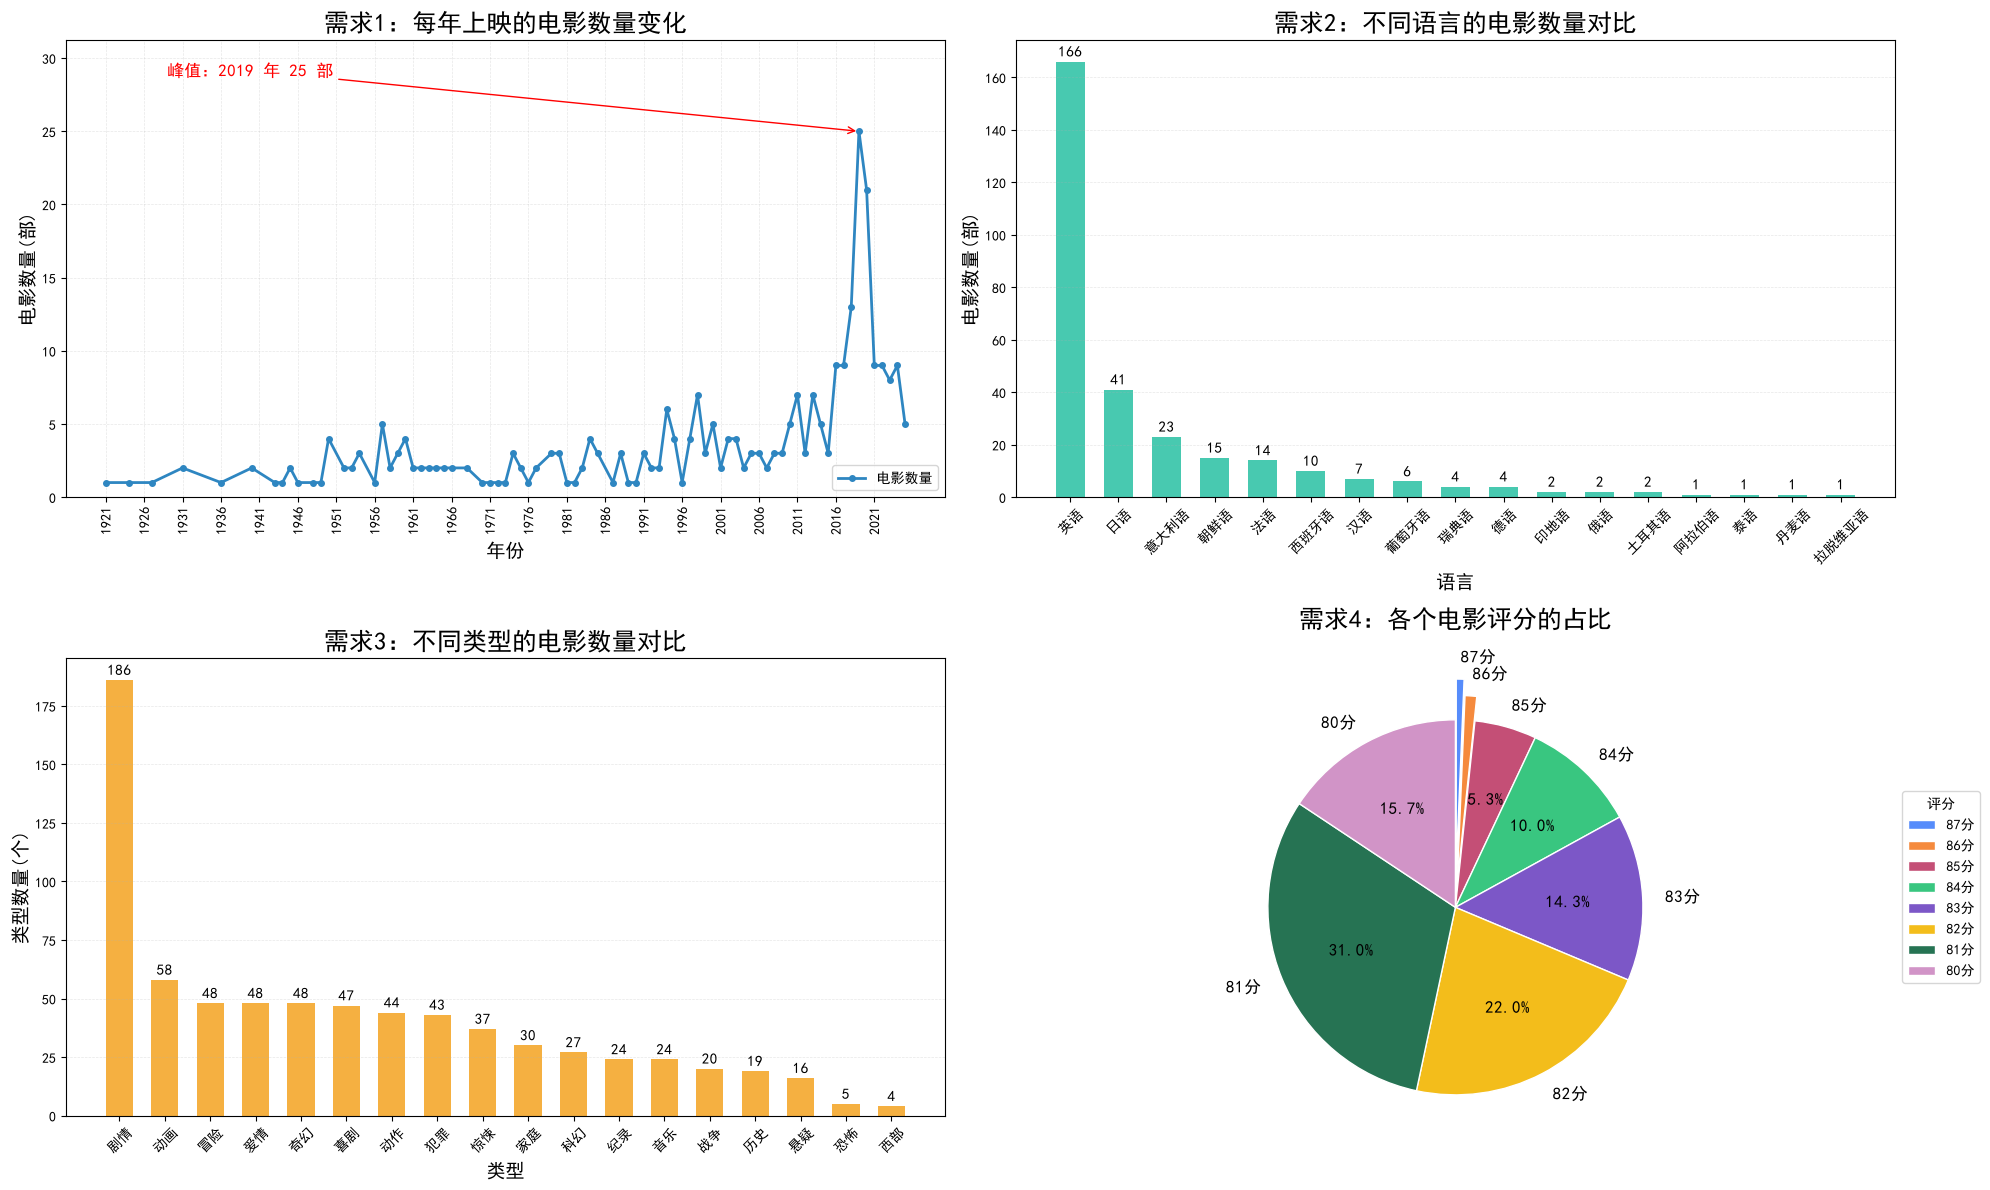

图片已保存到 resours/10.电影数据统计可视化.png


In [14]:
# 创建 2 行 2 列的画布
figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12), dpi=100)

#---------- 图一：折线图（需求1：每年上映的电影数量变化）----------
axes1 = axes[0][0]
axes1.plot(year_stat.index, year_stat.values, color='#2E86C1', linewidth=2, marker='o', markersize=4, label='电影数量')
axes1.set_title('需求1：每年上映的电影数量变化', fontsize=18)
axes1.set_xlabel('年份', fontsize=14)
axes1.set_ylabel('电影数量(部)', fontsize=14)
# 年份跨度一百多年且不连续，刻度每 5 年显示一个并旋转 90 度，避免文字挤在一起
axes1.set_xticks(range(year_stat.index.min(), year_stat.index.max() + 1, 5))
axes1.tick_params(axis='x', rotation=90)
axes1.grid(linestyle='--', alpha=0.3)
axes1.legend()
# y 轴留出空间，并把峰值年份标注在空白处（箭头指向峰值点），结论一目了然
axes1.set_ylim(0, year_stat.max() * 1.25)
axes1.annotate(f'峰值：{year_stat.idxmax()} 年 {year_stat.max()} 部',
               xy=(year_stat.idxmax(), year_stat.max()),
               xytext=(year_stat.index.min() + 8, year_stat.max() * 1.15),
               arrowprops={'arrowstyle': '->', 'color': 'red'},
               color='red', fontsize=12)

#---------- 图二：柱状图（需求2：不同语言的电影数量）----------
axes2 = axes[0][1]
bars2 = axes2.bar(language_stat.index, language_stat.values, width=0.6, color='#48C9B0')
axes2.set_title('需求2：不同语言的电影数量对比', fontsize=18)
axes2.set_xlabel('语言', fontsize=14)
axes2.set_ylabel('电影数量(部)', fontsize=14)
axes2.tick_params(axis='x', rotation=45)         # 语言有 17 种，标签旋转 45 度
axes2.bar_label(bars2, fontsize=11, padding=2)   # 在柱子上方标出数量
axes2.grid(axis='y', linestyle='--', alpha=0.3)

#---------- 图三：柱状图（需求3：不同类型的电影数量）----------
axes3 = axes[1][0]
bars3 = axes3.bar(genre_stat.index, genre_stat.values, width=0.6, color='#F5B041')
axes3.set_title('需求3：不同类型的电影数量对比', fontsize=18)
axes3.set_xlabel('类型', fontsize=14)
axes3.set_ylabel('类型数量(个)', fontsize=14)
axes3.tick_params(axis='x', rotation=45)         # 类型有 18 种，标签旋转 45 度
axes3.bar_label(bars3, fontsize=11, padding=2)
axes3.grid(axis='y', linestyle='--', alpha=0.3)

#---------- 图四：饼状图（需求4：各个电影评分的比例）----------
axes4 = axes[1][1]
# 占比很低的扇形太小，向外“炸开”一点（占比越低炸得越远），标签才不会互相压住
explode = [0.2 if ratio < 1 else 0.12 if ratio < 3 else 0 for ratio in score_percent.values]
axes4.pie(score_stat.values,
          labels=[f'{score}分' for score in score_stat.index],
          explode=explode,
          autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '',   # 小于 3% 的扇形不在内部标百分比，避免文字溢出
          startangle=90,              # 从 90 度开始，比例最大的扇区落在右上方
          counterclock=False,         # 顺时针排列（80 → 87 分）
          labeldistance=1.12,
          radius=0.92,                # 略微缩小饼图，给炸开的小扇区标签留出空间
          textprops={'fontsize': 12},
          wedgeprops={'edgecolor': 'white', 'linewidth': 1})
axes4.set_title('需求4：各个电影评分的占比', fontsize=18, pad=22)   # pad 留出空间，避免和炸开的“87分”标签相碰
axes4.axis('equal')                   # 保证饼图是正圆
axes4.legend(title='评分', loc='center left', bbox_to_anchor=(1.0, 0.5))

#---------- 保存图片并显示 ----------
plt.tight_layout()
plt.savefig('resours/10.电影数据统计可视化.png', dpi=100, bbox_inches='tight')
plt.show()
print('图片已保存到 resours/10.电影数据统计可视化.png')

## 五、分析结论

**需求 1（每年上映的电影数量变化）**
- 300 部电影分布在 1921—2025 共 82 个年份上，折线整体呈上升趋势：早期每年只有 1~2 部，1950 年代和 1990 年代各有一次小高峰（22 部、33 部）。
- 2010 年以后明显增多：2018 年 13 部、**2019 年 25 部（峰值）**、2020 年 21 部；2010 年至今共 147 部，接近总数的一半。

**需求 2（不同语言电影数量对比）**
- 英语电影 166 部（55.33%）遥遥领先，超过一半；其次是非英语片中的日语 41 部（13.67%）、意大利语 23 部（7.67%）、朝鲜语 15 部（5.00%）、法语 14 部（4.67%）。
- 其余 12 种语言都不超过 10 部，最少的几种只有 1 部，语言分布非常集中。

**需求 3（不同类型电影数量对比）**
- 一部电影可能有多个类型，300 部电影共 728 个类型标签，平均每部 2.43 个。
- 剧情类 186 个（占标签总数 25.55%）断层第一；其后是动画 58 个，冒险、爱情、奇幻各 48 个，喜剧 47 个；题材小众的恐怖（5 个）和西部（4 个）最少。
- 《心灵奇旅》的类型最多，同时包含动画、家庭、喜剧、奇幻、剧情、音乐 6 种。

**需求 4（各个评分的比例）**
- 评分集中在 80~85 分区间：81 分最多（93 部，31.00%），82 分次之（66 部，22.00%），两者合计占 53%；80 分 47 部（15.67%）。
- 评分越高数量越少：85 分 16 部（5.33%）、86 分 3 部（1.00%）、87 分只有 2 部（0.67%），整体平均分 81.95 分，说明高分电影非常稀缺。